<a href="https://colab.research.google.com/github/sumitpaul398/ML-projects/blob/main/18_Nov_K_Means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

import libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
from sklearn.datasets import make_blobs

In [ ]:
blob_centers = np.array(
    [[0.2, 2.3],
     [-1.5, 2.3],
     [-2.8, 1.8],
     [-2.8, 2.8],
     [-2.8, 1.3]]
)
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])

In [ ]:
x, y = make_blobs(n_samples= 2000, centers=blob_centers, cluster_std=blob_std, random_state=7)

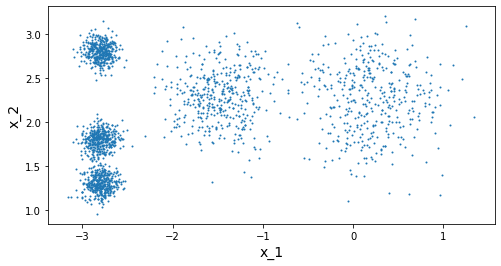

In [ ]:
def plot_clusters(x, y=None):
  plt.scatter(x[:,0], x[:,1], c=y, s=1)
  plt.xlabel("x_1", fontsize=14)
  plt.ylabel("x_2", fontsize=14, rotation=90)

plt.figure(figsize=(8,4))
plot_clusters(x)
plt.show()

In [ ]:
from sklearn.cluster import KMeans

In [ ]:
k=5
init = "k-means++"
kmeans = KMeans(n_clusters= k, init= init, random_state=42)
y_pred = kmeans.fit_predict(x)


In [ ]:
kmeans.cluster_centers_

array([[-2.80389616,  1.80117999],
       [ 0.20876306,  2.25551336],
       [-2.79290307,  2.79641063],
       [-1.46679593,  2.28585348],
       [-2.80037642,  1.30082566]])

In [ ]:
print(blob_centers)

[[ 0.2  2.3]
 [-1.5  2.3]
 [-2.8  1.8]
 [-2.8  2.8]
 [-2.8  1.3]]


make predictions

In [ ]:
x_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])
kmeans.predict(x_new)

array([1, 1, 2, 2], dtype=int32)

In [ ]:
def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=35, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=12,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                cmap="Pastel2")
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                linewidths=1, colors='k')
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)

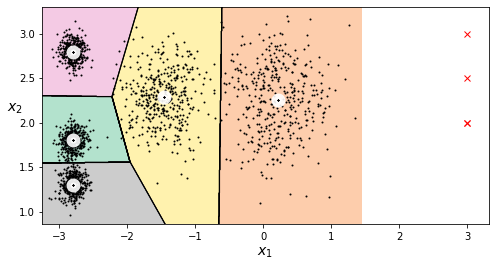

In [ ]:
plt.figure(figsize= (8,4))
plot_decision_boundaries(kmeans, x)

for i in range(4):
  plt.plot(x_new[1][0], x_new[i][1], 'rx')

plt.show()

In [ ]:
kmeans.transform(x_new)

array([[2.81093633, 0.32995317, 2.9042344 , 1.49439034, 2.88633901],
       [5.80730058, 2.80290755, 5.84739223, 4.4759332 , 5.84236351],
       [1.21475352, 3.29399768, 0.29040966, 1.69136631, 1.71086031],
       [0.72581411, 3.21806371, 0.36159148, 1.54808703, 1.21567622]])

In [ ]:
kmeans.inertia_

211.5985372581684

In [ ]:
kmeans_rnd_10_inits = KMeans(n_clusters=5, init="random", n_init= 10, algorithm="full", random_state=2)
kmeans_rnd_10_inits.fit(x)

KMeans(algorithm='full', init='random', n_clusters=5, random_state=2)

In [ ]:
kmeans_rnd_10_inits.inertia_

211.5985372581684

k-means++

In [ ]:
kmeans = KMeans(n_clusters=5, random_state=2)
kmeans.fit(x)

KMeans(n_clusters=5, random_state=2)

In [ ]:
kmeans.inertia_

211.5985372581684